# SQDMetal two-transmon example — two pocket transmons joined by a straight coupler (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/two_transmon.ipynb`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/two_transmon.md`): a Quantum
Metal design for an SQDMetal Palace eigenmode run (2 modes from 5 GHz, silicon 500 µm), with no stored outputs.
Two floating `TransmonPocket`s 1 mm apart; their facing connection pads are joined by a straight CPW
(`RouteStraight`) — a direct capacitive link with no resonator, a minimal two-qubit eigenmode / EPR test. There are
no launchers or pads (an eigenmode model only).

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | Metal chip 2.2 × 1.8 mm centred on (0.5, 0) mm | the 7.5 × 7.5 mm Quantcore die with its frame (dicing L's, alignment grids, boundary, device ID "SQD-2T"); the source area sits in its centre, so every coordinate is the source's + (600, 900) µm |
| pads | none (Palace ports on the junctions) | none: nothing to put on the pad rule (`frame.pad_edge`, 100 µm) |
| substrate | silicon, 500 µm | sapphire 650 µm, εr 10.25 |
| junctions | Palace lumped L_J 13 / 9 nH, C_J 0 | Quantcore trilayer junctions at the two ends of the 40–50 kΩ window: Q1 50 kΩ (L_J ≈ 7.5 nH), Q2 40 kΩ (≈ 6.0 nH) — the source's detuning order |
| cheese | none (the source only meshes the design for Palace: `eigen_sim.add_ground_plane()`, no holes) | the PDK band (chip `cheese` `"auto"`): 5 µm squares, 20 µm gaps, 3 rows round the 3/0 keep-outs, at least 4 µm clear of 3/0 |
| components, positions | `TransmonPocket` × 2, `RouteStraight` | kept: Metal components through the `metal:` wrapper, the source options and positions |
| placement | — | centred in the die (checked: no shift) |

**Not reproduced:** the `hfss_wire_bonds` flag (an HFSS rendering option).

The notebook walks through the build step by step: setup and the PDK → junctions → die and frame → pads →
components → routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; set it to `True` to solve the jobs in a new batch
AEDT 2024 R1 (if one is installed). `FULL_FAB = False` skips the fab-only corner rounding in the mask step
(`qcc mask` writes the complete file). Step snapshots go to `build/snapshots/` (not kept in the repo); the final
ones next to the notebook.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "two_transmon"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 600, 900                                # Metal's chip is centred on (0.5, 0) mm

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junctions from the PDK rule.** `trilayer_junction("metal:TransmonPocket", lj_nH=...)` gives the cell
parameters of a Quantcore trilayer junction (`junction_type` + `junction_params`) and the drawn junction's L_J /
C_J for the LOM. The source detunes the pair with its Palace junctions (13 / 9 nH, a ratio of 1.44, wider than the
window's 1.25); the rebuild keeps that order at the two ends of the 40–50 kΩ window: Q1 R_n 50 kΩ (L_J ≈ 7.5 nH,
C_J ≈ 13.5 fF), Q2 40 kΩ (≈ 6.0 nH, ≈ 16.8 fF). Expected f_q ≈ 7.0 / 7.8 GHz (the source's junctions gave
5.9 / 7.2 GHz on this layout).

In [4]:
from quantcore_circuits.circuit.bridges import lj_from_rn
JJP_Q1, JJ_Q1 = trilayer_junction("metal:TransmonPocket", lj_nH=lj_from_rn(50e3))   # R_n 50 kΩ
JJP_Q2, JJ_Q2 = trilayer_junction("metal:TransmonPocket", lj_nH=lj_from_rn(40e3))   # R_n 40 kΩ
print("Q1", JJP_Q1, JJ_Q1)
print("Q2", JJP_Q2, JJ_Q2)

Q1 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 7.482691894823213}} {'Lj_nH': 7.4827, 'Cj_fF': 13.5}
Q2 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 5.986153515858571}} {'Lj_nH': 6.0129, 'Cj_fF': 16.8}


## 3 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so that the source's 2.2 × 1.8 mm
area sits in its centre. The PDK frame is drawn on it: L dicing markers (1000/0) and a 3 × 3 alignment grid
(1001/0) in each corner area, the chip boundary (100/0) and the device ID `name_chip` on a free edge. The chip
`cheese` stays `"auto"`: the source has no cheese, so the build draws the PDK band once there is metal to band.

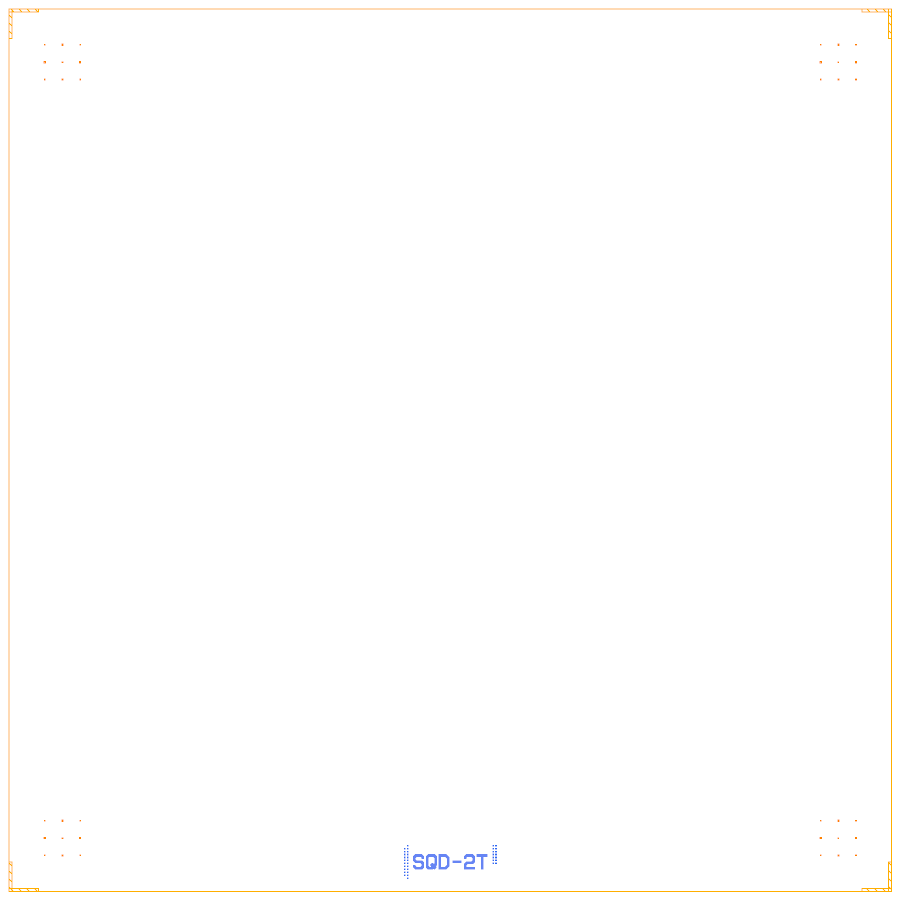

In [5]:
d = Designer("two_transmon", box=(-2650, -2850, 4850, 4650), chip={"name_chip": "SQD-2T"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(900, 900), width=360);

## 4 · Pads and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`d.add(..., edge="auto")`). The source is a Palace eigenmode model with no pads or launchers — its only ports are
the junctions — so there is nothing to place here and the table is empty.

In [6]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## 5 · Components

Two Quantum Metal `TransmonPocket`s through the `metal:` wrapper (the Metal options are the cell parameters; bare
numbers on length options are µm): `pad_width` 425 µm, `pocket_height` 650 µm, the other options Metal's
defaults (pads 90 µm high, 30 µm apart, 650 µm pocket). Each has one `readout` connection pad, 200 µm wide, at
the top corner facing the other qubit (`loc_W` ±1, `loc_H` +1). The wrapper draws the Quantcore trilayer junction
across the pad gap (`junction_type` from step 2), and its ports are Metal's pin names (`readout`) plus the
junction attachment points `squid_a` / `squid_b`.

<metal:TransmonPocket Q1 ports=['readout', 'squid_a', 'squid_b']>


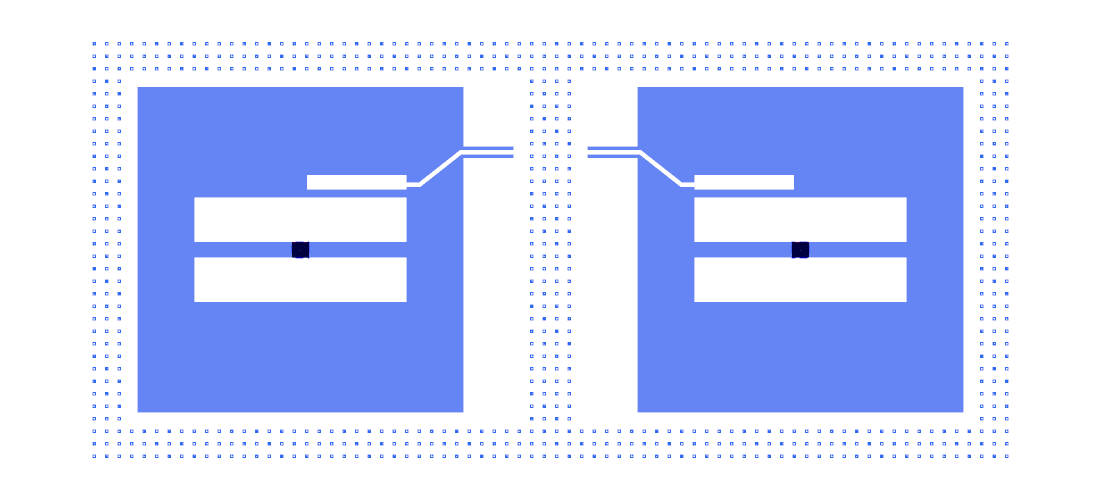

In [7]:
POCKET = dict(pad_width=425, pocket_height=650)
with d.batch():
    q1 = d.add("Q1", "metal:TransmonPocket", at=(X0, Y0), junction=JJ_Q1, **JJP_Q1,
               connection_pads={"readout": {"loc_W": 1, "loc_H": 1, "pad_width": 200}}, **POCKET)
    q2 = d.add("Q2", "metal:TransmonPocket", at=(X0 + 1000, Y0), junction=JJ_Q2, **JJP_Q2,
               connection_pads={"readout": {"loc_W": -1, "loc_H": 1, "pad_width": 200}}, **POCKET)
print(q1)
snap(d, STEPS / "2_components.png", box=(X0 - 600, Y0 - 500, X0 + 1600, Y0 + 500), size=(1100, 500), width=520);

## 6 · Routes

The coupler is one straight CPW between the two `readout` pins (10/6 µm, the PDK default; the source's
`RouteStraight`). `r=20` only sets the bend radius of the port stubs, since the pins are 150 µm apart on one line.

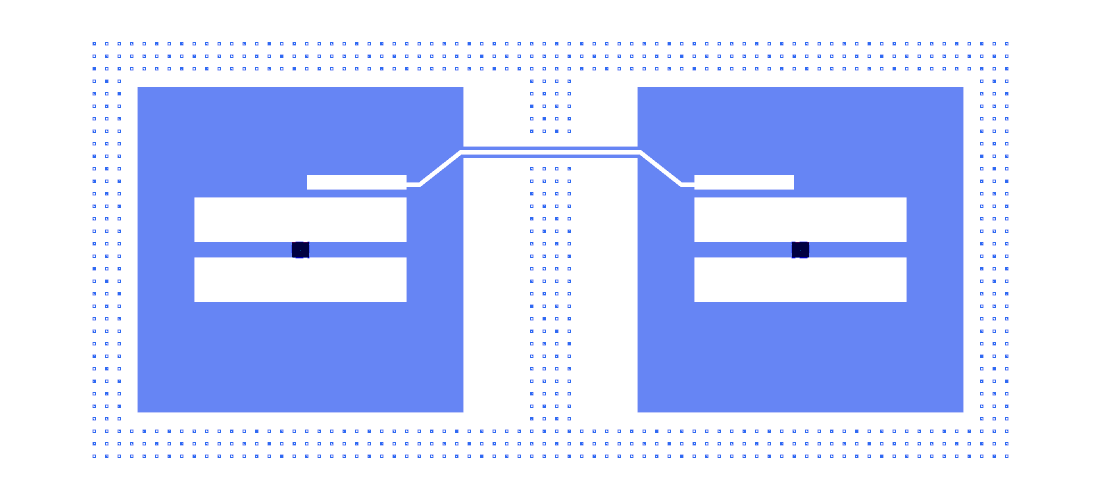

coupler 150.0 µm


In [8]:
d.route("COUPLER", q1.readout, q2.readout, r=20)    # straight; r only sets the port stubs
snap(d, STEPS / "3_routes.png", box=(X0 - 600, Y0 - 500, X0 + 1600, Y0 + 500), size=(1100, 500), width=520)
print("coupler", round(d.result.route_lengths()["COUPLER"], 1), "µm")

**Sim group, centring, save.** One sim group holds both qubits and the coupler (a Q3D C-matrix and an eigenmode /
EPR job, the source's own analysis being a Palace eigenmode run). `center_in_die` checks the PDK placement rule —
the content is centred, so nothing moves — and the design is saved: `two_transmon.json` is what DRC, LOM, FEM and
`qcc` read.

In [9]:
d.sim_group("Q1Q2", ["Q1", "Q2", "COUPLER"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "two_transmon.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer two_transmon: 2 instances, 1 routes, live=False> → examples\designs\sqdmetal\two_transmon.json


## 7 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here: **no errors**; four `dangling_port` warnings, the `TransmonPocket` junction attachment points
`squid_a` / `squid_b` (the qubit cell draws its own junction, nothing is routed there); one PDK design warning,
`pdk_rn` on Q1: its junction sits exactly on the window's 50 kΩ edge (the source's detuning kept at the edge of
the window; flagged, not retuned).

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 1 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | Q1.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 1 | Q1: junction R_n 50.0 kΩ is outside the PDK window 40–50 kΩ (L_J 7.4827 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | Q1: junction R_n 50.0 kΩ is outside the PDK window 40–50 kΩ (L_J 7.4827 nH) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes. A
`TransmonPocket` is a floating transmon — two pad nodes (`island1`, `island2`) with C to ground and between them,
the junction across them — plus one node per connection pad. The straight coupler joins the two `readout` pads
into one conductor, so Q1 and Q2 couple through C(Q1 pad → coupler) and C(coupler → Q2 pad) in series. No
resonators, feedlines or controls.

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1 / Q2 ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("Q1.", "Q2.")))))

**6 nodes · 14 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout`, `Q2.readout` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 7.48 nH, Cj 13.5 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 24.8 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 2.6 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 37.5 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 34.3 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 34.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 26.2 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q2_readout` | C | `Q2.island1` – `Q1.readout` | 24.8 fF |
| `Cf_Q2_readout` | C | `Q2.island2` – `Q1.readout` | 2.6 fF |
| `Cc_Q2_readout` | C | `Q1.readout` – `gnd` | 37.5 fF |

**Unconnected ports:** none

**Q1 / Q2 ports → circuit nodes:**

| port | node |
|---|---|
| `Q1.readout` | `Q1.readout` |
| `Q1.squid_a` | `Q1.island2` |
| `Q1.squid_b` | `Q1.island1` |
| `Q2.readout` | `Q1.readout` |
| `Q2.squid_a` | `Q2.island2` |
| `Q2.squid_b` | `Q2.island1` |

## 9 · LOM simulation

QuCat finds the normal modes (frequencies, anharmonicities); QuTiP diagonalises the dressed Hamiltonian of both
qubits (f_q, α) and gives the static ZZ between them. No targets are stated in the source; the detuning comes
from the two junctions. Expected: f_q ≈ 7.0 / 7.7 GHz, α ≈ −350 / −325 MHz (small pads, small C_Σ), ZZ of a few
MHz (a strong direct coupling at 0.7 GHz detuning).

In [12]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))
display(Markdown(zz_md(res)))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 7.3957 | 0 | 311.3 | J_Q1 1.00 |
| Q2 | qubit | 8.0422 | 0 | 295.8 | J_Q2 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 7.0677 | – |
| `Q1.alpha_MHz` | -349.22 | – |
| `Q2.f_q_GHz` | 7.7325 | – |
| `Q2.alpha_MHz` | -324.48 | – |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
|  | Q1-Q2 | -3877 | yes | no |

## 10 · FEM: send the jobs
The LOM uses analytic capacitance estimates; a finite-element job measures them. `send_fem_jobs` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, each Ansys job is solved in a **new batch,
non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [13]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1Q2 · eigenmode_epr | `build/jobs/two_transmon_Q1Q2_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction` | `Q1.island2`, `Q2.island2`, `Q1.island1`, `Q2.island1`, `Q1.readout` |
| Q1Q2 · q3d_cmatrix | `build/jobs/two_transmon_Q1Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · waveguide · `Q1.readout`<br>4 · waveguide · `Q2.readout` | `Q1.island2`, `Q2.island2`, `Q1.readout`, `Q1.island1`, `Q2.island1` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`:
the C-matrix replaces the component estimates branch by branch (matched by net name), and the table compares the two;
`simulate(filled)` re-runs the LOM on the extracted values. Until a solve has run, the cell says which jobs are still
waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1Q2 · eigenmode_epr, Q1Q2 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

A design change is a parameter change followed by a rebuild and a new LOM run. Here: give Q2 the PDK nominal
junction (R_n 45 kΩ, L_J 6.73 nH) instead of the 40 kΩ one. Q2's f_q drops by ≈ 0.35 GHz towards Q1; the
detuning (≈ 0.32 GHz) is then about one anharmonicity, where |11⟩ comes close to |02⟩, so the static ZZ grows by
an order of magnitude (≈ −4 → ≈ −56 MHz). This is why the source detunes the pair. The change is made on a copy
(`design_copy`), so `two_transmon.json` keeps the source's detuning.

In [15]:
d2 = design_copy(DESIGN)
JJP_N, JJ_N = trilayer_junction("metal:TransmonPocket", lj_nH=lj_from_rn(45e3))
d2["Q2"].set(junction=JJ_N, **JJP_N)
after = simulate_lom(d2.lom(), d2.design)
display(Markdown("**Q2 junction: R_n 40 → 45 kΩ**\n\n" + params_delta_md(res, after)))
display(Markdown("**ZZ before → after:**\n\n" + zz_md({"before": res, "after": after})))

**Q2 junction: R_n 40 → 45 kΩ**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1.f_q_GHz` | 7.0677 | 7.0661 | -0.001608 |
| `Q1.alpha_MHz` | -349.22 | -346.95 | +2.268 |
| `Q2.f_q_GHz` | 7.7325 | 7.3886 | -0.344 |
| `Q2.alpha_MHz` | -324.48 | -286.88 | +37.6 |

**ZZ before → after:**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| before | Q1-Q2 | -3877 | yes | no |
| after | Q1-Q2 | -5.585e+04 | yes | no |

## 13 · Build and export

**The design file.** `two_transmon.json` (saved in step 6) is the whole design:
`qcc build examples/designs/sqdmetal/two_transmon.json` rebuilds `build/two_transmon.oas` + its sidecar, and the
KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and
spacer 50/0 with the 51–53/0 dose gradient, and the frame (100/0, 1000/0, 1001/0). **Cheese:** the source has none,
so the PDK band stands — drawn in the build (`cheese_source` `build`), 3 rows of 5 µm squares round the 3/0
keep-outs, at least 4 µm clear of them. Corner rounding is fab-only (`FULL_FAB`); `qcc mask examples/designs/sqdmetal/two_transmon.json`
writes the complete file.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 759 |
| 2/0 | JJ_STRAIGHT | 2 |
| 3/0 | M3 | 756 |
| 4/0 | JJ_BENT | 2 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 752 holes on the mask.

→ `build/two_transmon_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [17]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1Q2", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}
airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

Both pockets with the coupler; Q1's trilayer junction across the pad gap; the coupler landing on Q2's connection
pad; the die frame's south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and Q1's junction in
the **fab view** (the mask from step 13: base etch 1/0 with the PDK cheese band, the 3/0 keep-out, the junction
layers 2/0 + 4/0 + 50–53/0). In the layout snapshots the chip boundary 100/0 is drawn as an outline and the cheese
band (KQC's ground-grid layer) is visible; the fab view shows the mask itself.

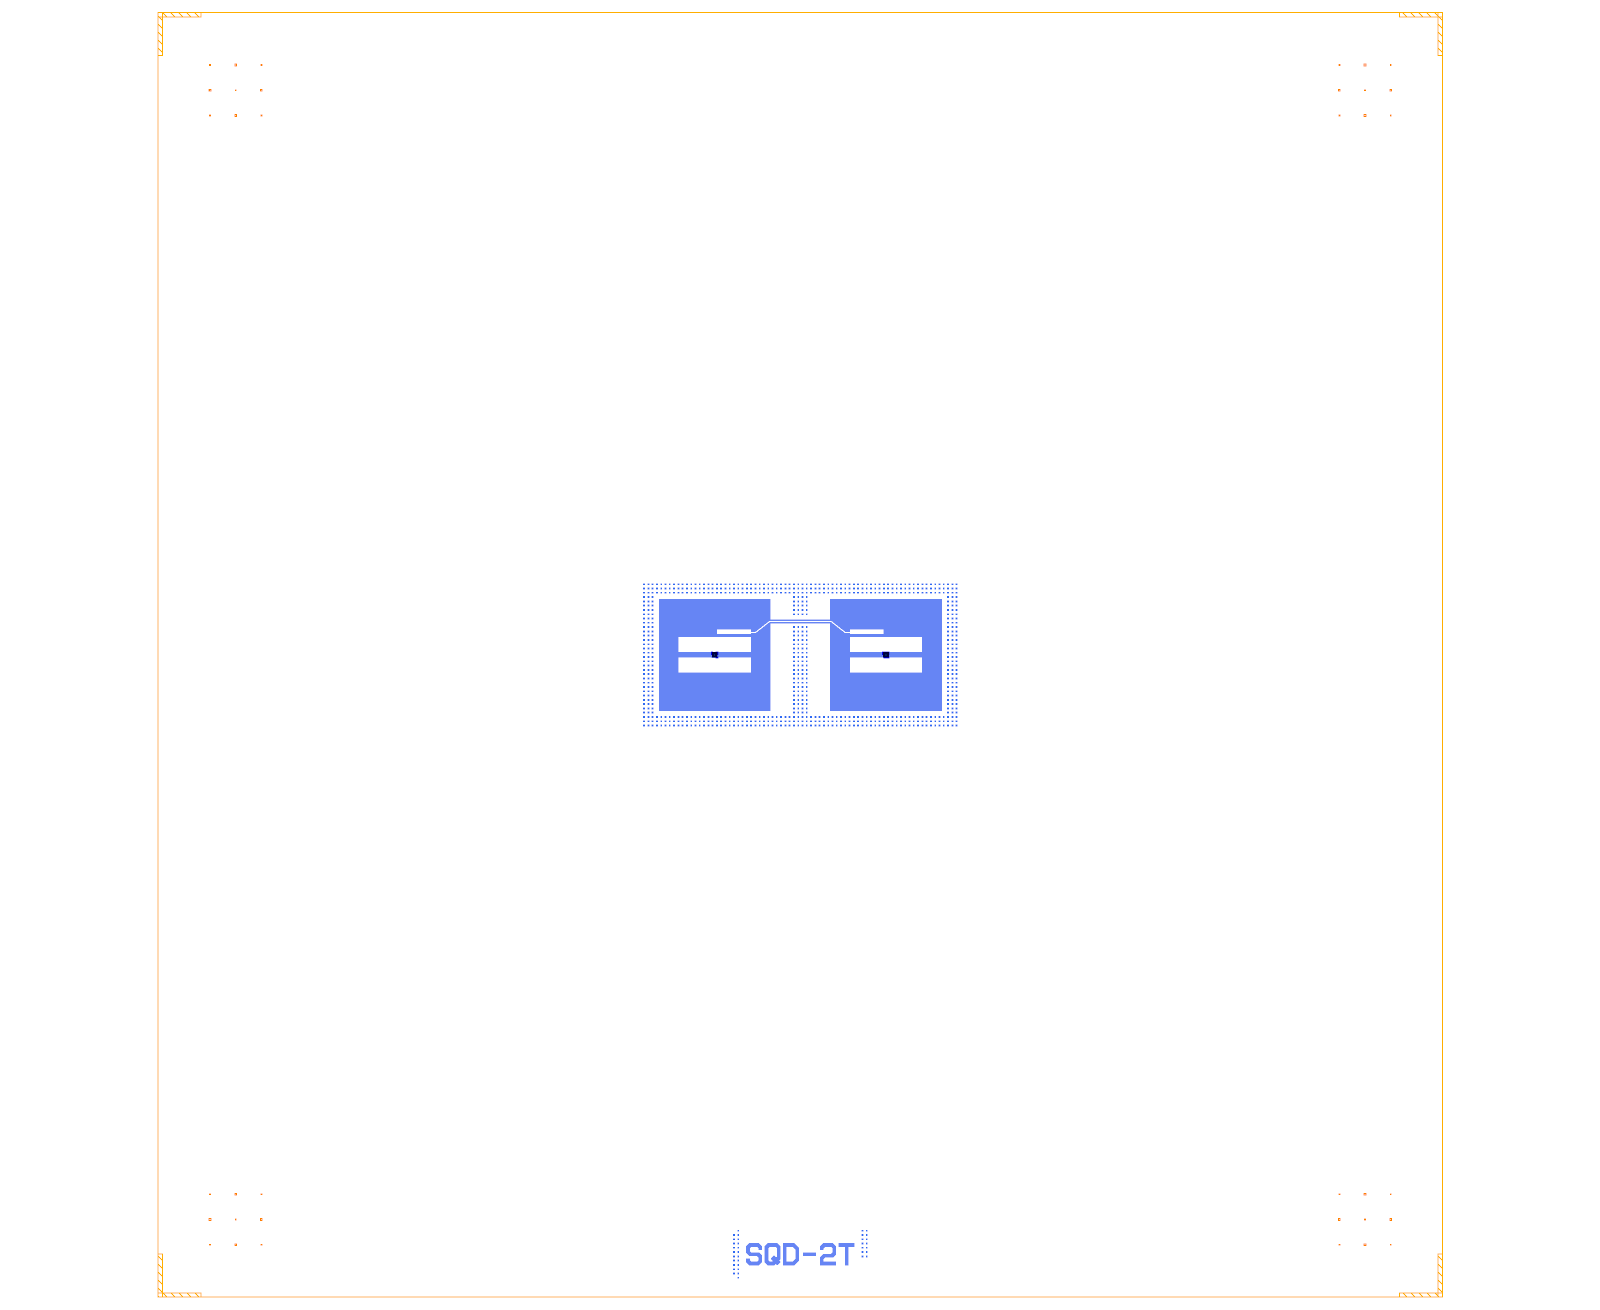

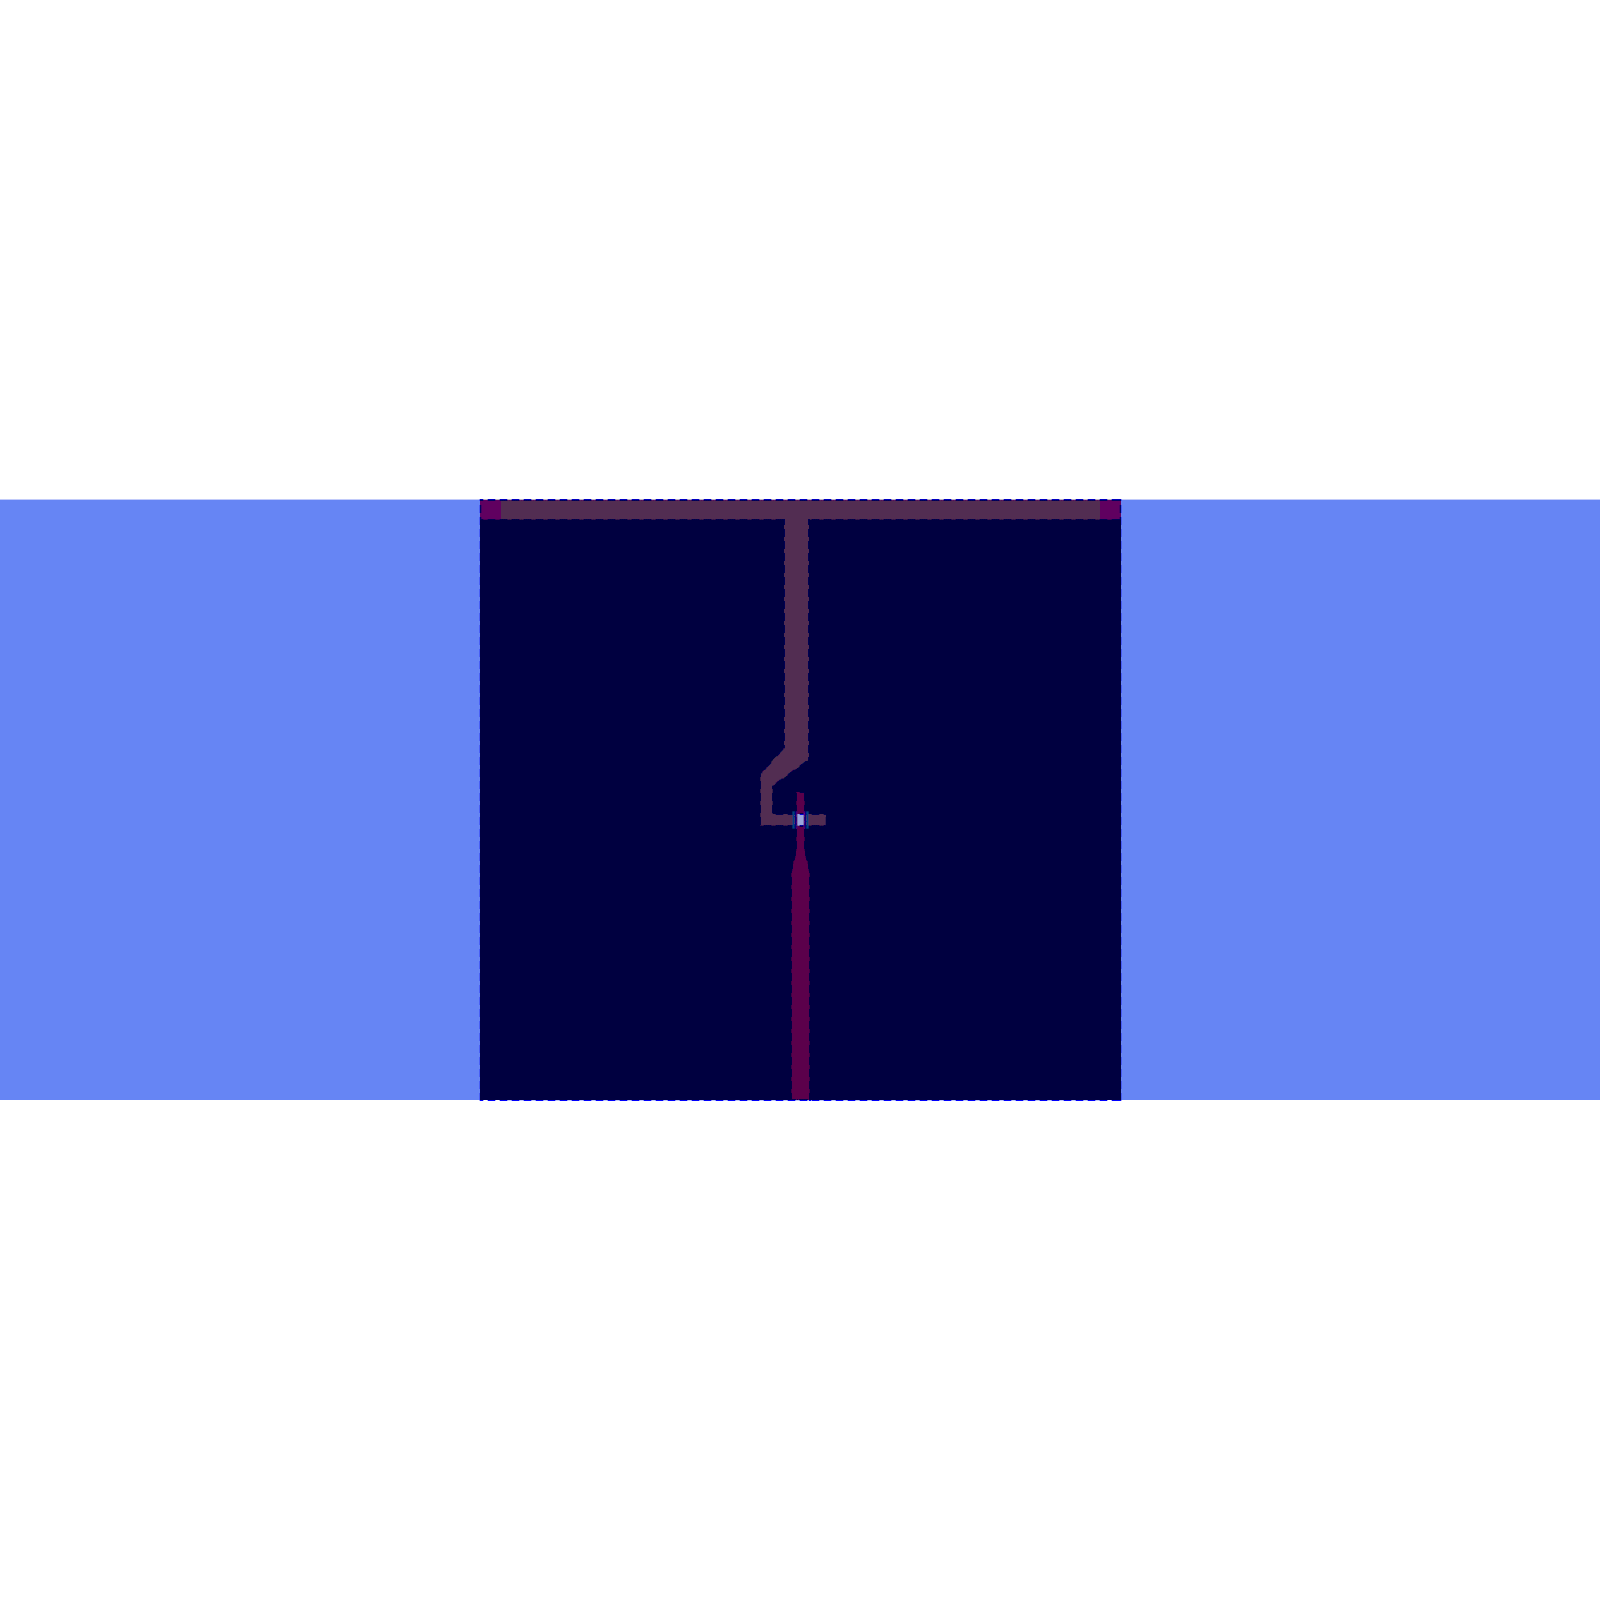

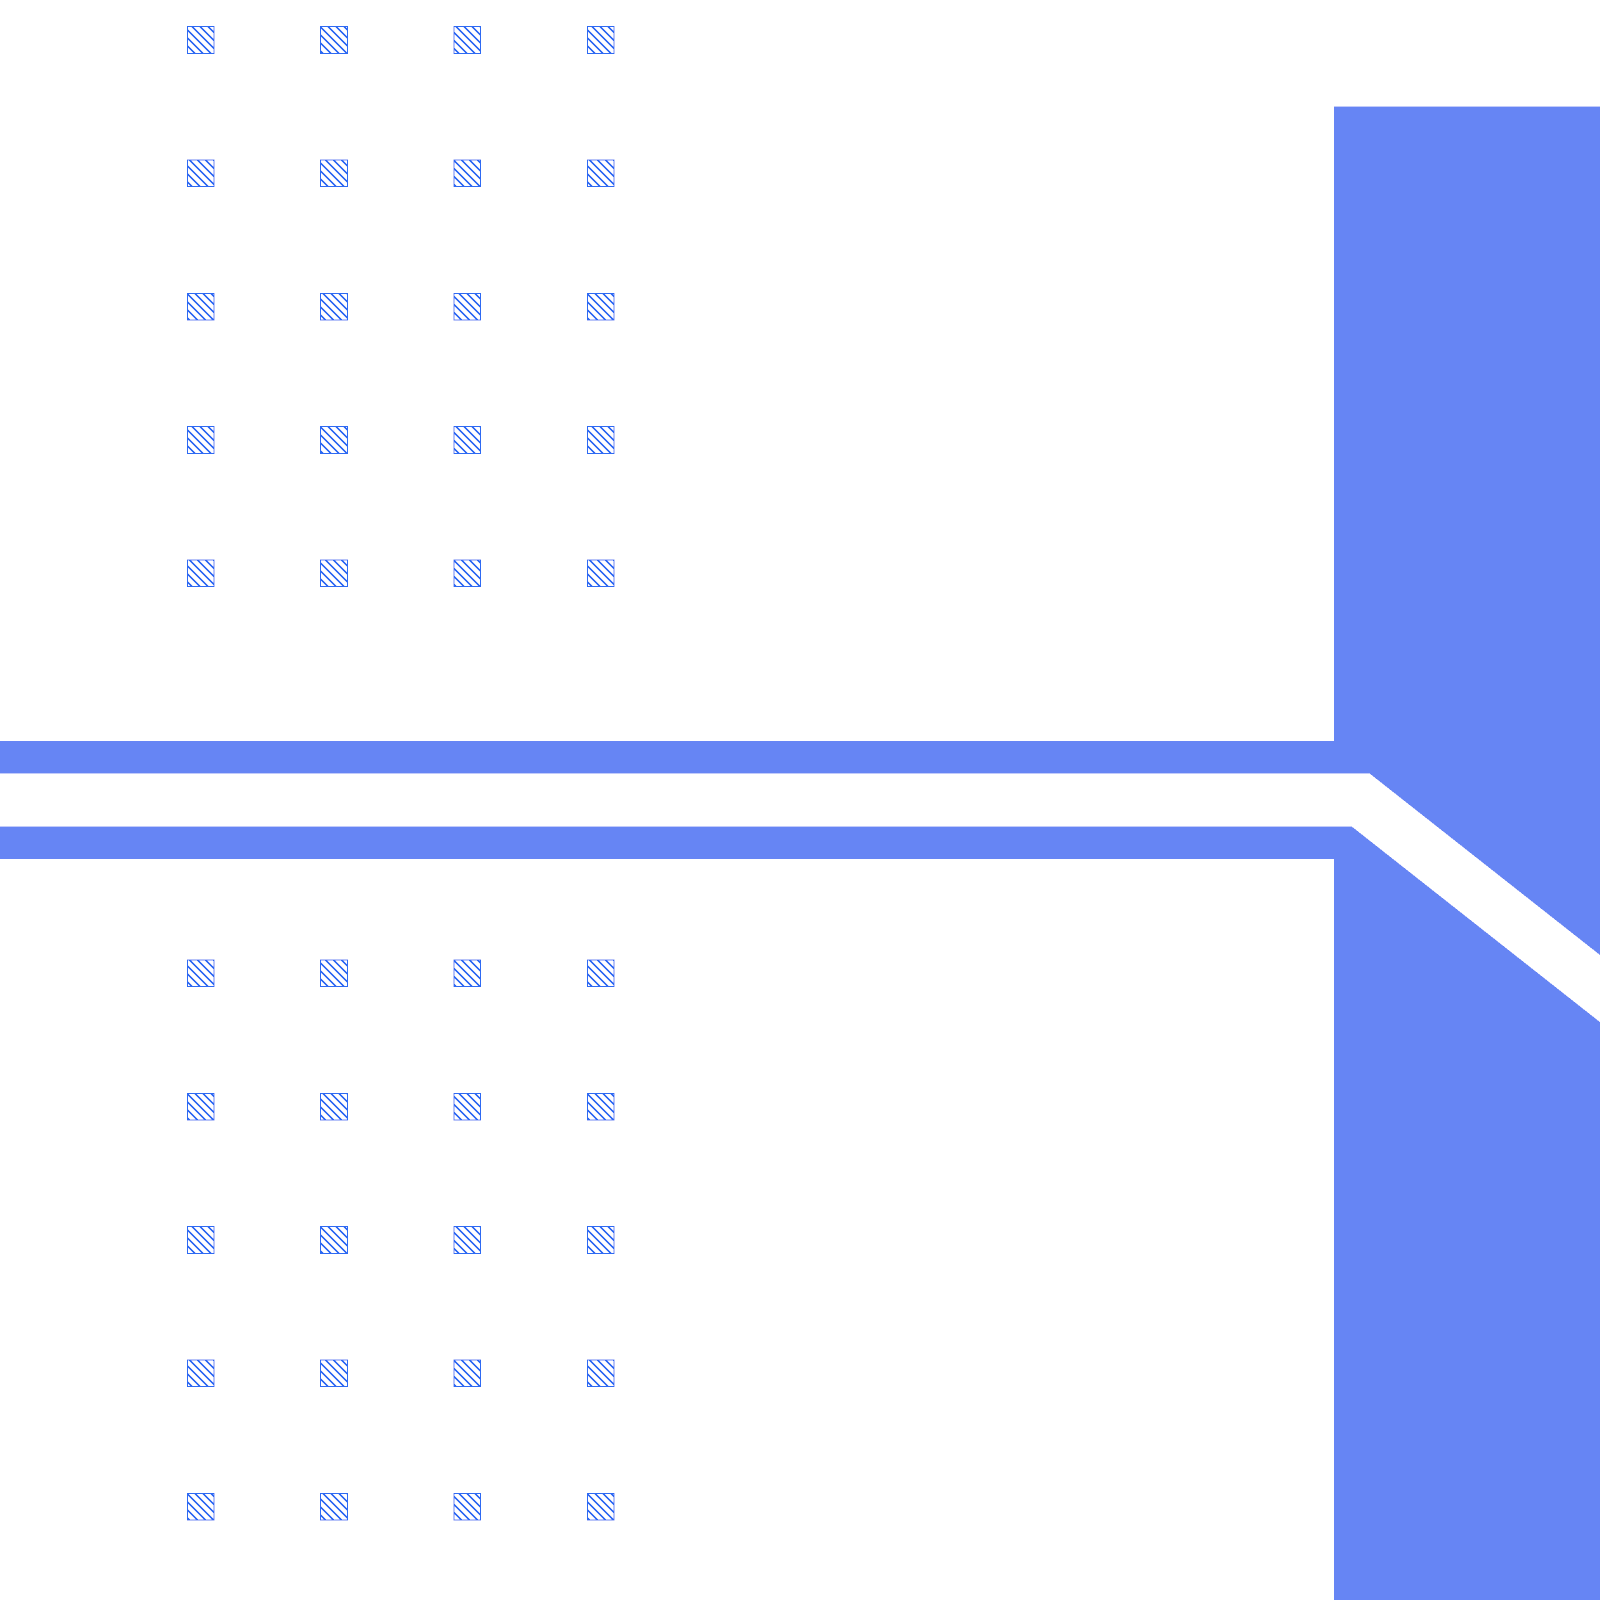

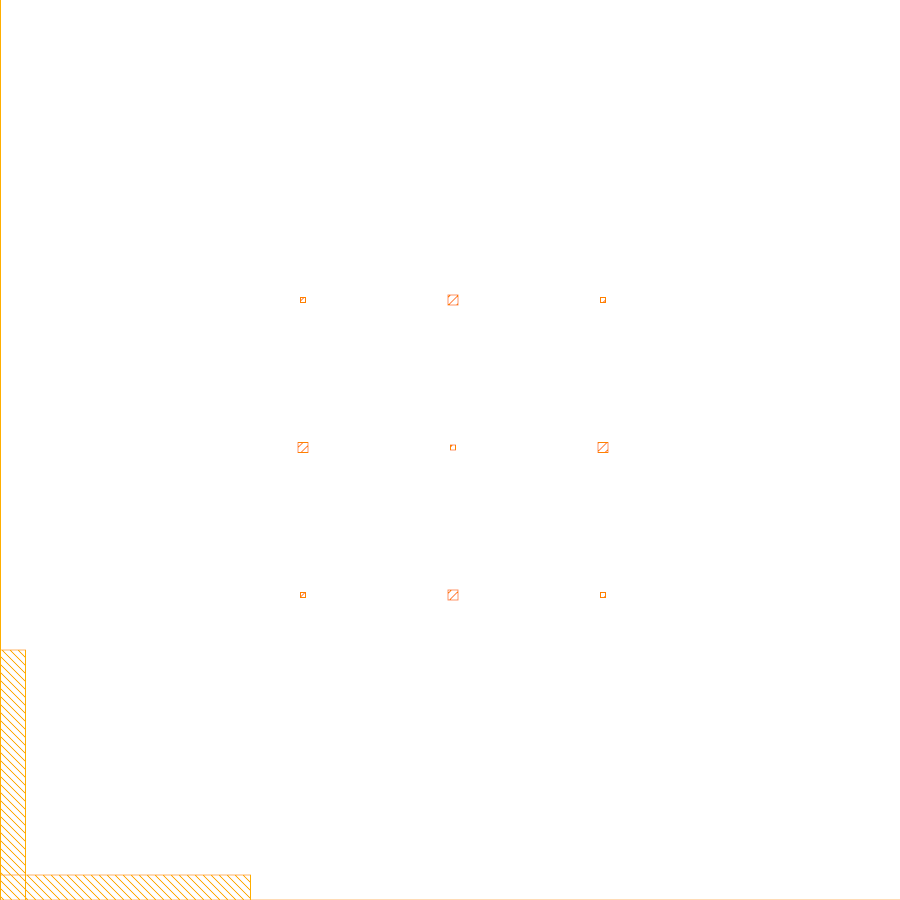

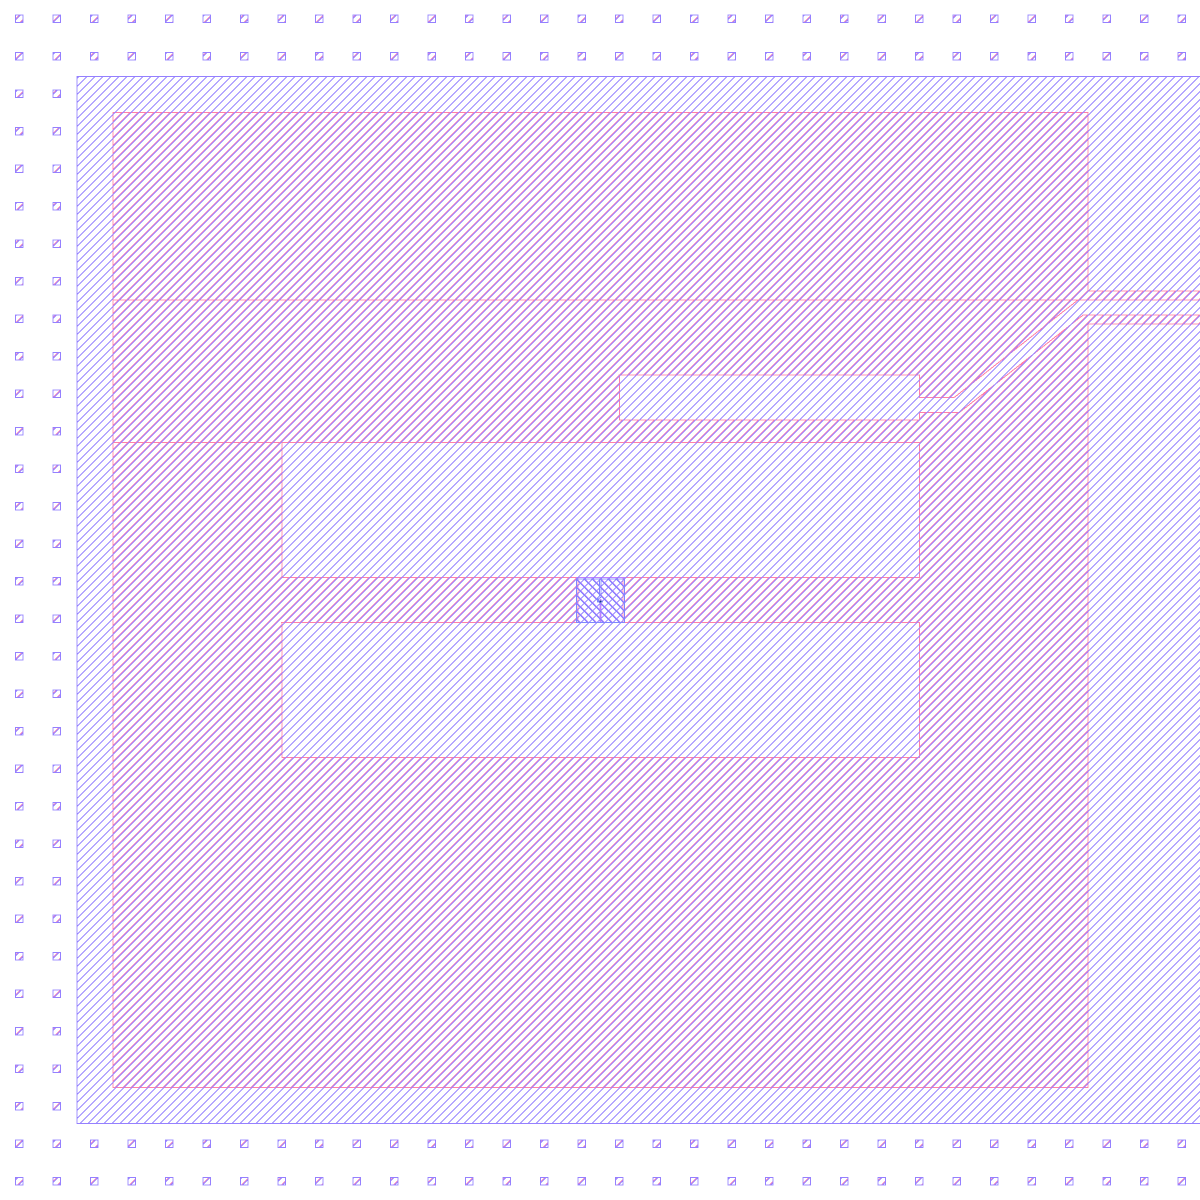

In [18]:
show_snapshot(d, OUT / "two_transmon.png", size=(1600, 1310))
show_snapshot(d, OUT / "two_transmon_jj.png", box=(X0 - 40, Y0 - 40, X0 + 40, Y0 + 40), width=300)
rx, ry = port_xy(d, "Q2.readout")
show_snapshot(d, OUT / "two_transmon_pad.png", box=(rx - 150, ry - 120, rx + 150, ry + 120), width=360)
show_snapshot(d, OUT / "two_transmon_frame.png", box=(-2650, -2850, -1750, -1950), size=(900, 900), width=300)
snap_file(Path("build") / "two_transmon_fab.oas", OUT / "two_transmon_fab_q1.png",
          box=(X0 - 400, Y0 - 400, X0 + 400, Y0 + 400), size=(1200, 1200), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | two `TransmonPocket`s with the source options and positions, the straight coupler between their facing connection pads, the detuning order Q1 < Q2, the eigenmode sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame (source area centred); sapphire instead of silicon; Quantcore trilayer junctions at R_n 50 / 40 kΩ (f_q ≈ 7.0 / 7.7 GHz instead of the source's L_J 13 / 9 nH); the PDK cheese band in the mask (the source has none) |
| **pads** | none in the source (eigenmode model): nothing for the pad rule (100 µm) |
| **PDK design warnings** | `pdk_rn` on Q1 (exactly on the 50 kΩ edge of the window) |
| **FEM** | a Q3D C-matrix and an eigenmode / EPR job exported to `build/jobs/two_transmon_Q1Q2_*`, not solved here |